# Step 14 (notebook): one pulsed exploratory scan

Same analysis as `14_pulsed_exploratory_scan.py`, but the scan folder is set below instead of in the terminal, and the results are shown here.

1. Set `DATA_PATH` to the folder with the scan's `.mat` files: a local folder or a folder on the NAS (on macOS a connected NAS is under `/Volumes/<share>/...`; an `smb://` address is translated to that).
2. Run all cells with the **t-difc-env** kernel (the project's environment, built from `requirements.txt`: Python 3.11, TensorFlow 2.13). In VS Code: *Select Kernel* (top right) > *Jupyter Kernel…* > `t-difc-env (Python 3.11)`. A kernel with TensorFlow ≥ 2.16 / Keras 3 cannot load the saved models and stops in the setup cell.

The folder is linked into `data/pulsed-exploratory-raw/<scan>/` and analysed with `independent_scan.analyse`, exactly as step 14 does. The scan is never grouped with the clearance cohort or with other scans. The `.mat` files are only read; everything is written to the local project: results in `results/pulsed-exploratory/<scan>/`, caches in `data/pulsed-exploratory-preprocessed/` and `data/pulsed-exploratory-als-cache/`. Rerunning uses the caches (the NAS must still be connected).

In [1]:
# ---- settings -------------------------------------------------------------------
DATA_PATH = "/Volumes/Public/Jane/ScidBg MM/261024-ScBgMM54-MM-tdT_Pulsed_D35"   # folder with the scan's .mat files
SCAN = None              # name of the results folder; None = the folder name of DATA_PATH

# candidate windows (last cells: detected peaks, artifacts)
SORT_BY = "time"         # "time" or "probability" (highest first)
MAX_WINDOWS = None       # None = all of them; a number = only the first ones after sorting (per cell)
WINDOWS_PER_PAGE = 24    # windows per figure (4 per row)

## Setup

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

HERE = os.path.abspath("")
SCRIPTS = HERE if os.path.exists(os.path.join(HERE, "common.py")) else os.path.join(HERE, "scripts")
sys.path.insert(0, SCRIPTS)
import common as mc
import independent_scan
import scan_figures as sf

%matplotlib inline
pd.set_option("display.width", 200)
print("python: ", sys.executable)
print("project:", mc.ROOT)
print("cut-off:", mc.CUT)

python:  /Users/mehrnoosh/Northeastern/Codes/t-DiFC-Claude/fusion_lr1e-4_wd_ls_pipeline/t-difc-env/bin/python
project: /Users/mehrnoosh/Northeastern/Codes/t-DiFC-Claude/fusion_lr1e-4_wd_ls_pipeline
cut-off: 0.6


## Link the scan folder

In [3]:
SCAN = independent_scan.link_scan(DATA_PATH, mc.PULSED_RAW_DIR, SCAN)   # same as step 14 with a path
link = os.path.join(mc.PULSED_RAW_DIR, SCAN)
mats = sorted(f for f in os.listdir(link) if f.endswith(".mat") and not f.startswith("."))
print(f"{SCAN}: {os.path.realpath(link)}\n{len(mats)} .mat file(s): {mats}")
if os.path.isdir(os.path.join(mc.COHORT_RAW_DIR, SCAN)):
    print(f"note: {SCAN} is also a clearance-cohort-raw folder (no cohort result is changed)")

261024-ScBgMM54-MM-tdT_Pulsed_D35: /Volumes/Public/Jane/ScidBg MM/261024-ScBgMM54-MM-tdT_Pulsed_D35
3 .mat file(s): ['261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat', '261024-ScBgMM54-MM-tdT_Pulsed_D35_3_F1.mat', '261024-ScBgMM54-MM-tdT_Pulsed_D35_5_F1.mat']


## Run the analysis (as step 14)

Preprocessing, split-overlap check, 5-seed scoring, summary, barcode, timeline, and window galleries of this scan (no clearance fit for pulsed exploratory scans).

In [4]:
summary = independent_scan.analyse(SCAN, mc.PULSED_RAW_DIR, mc.PULSED_PREP_DIR, mc.PULSED_ALS_DIR, mc.PULSED_DIR,
                                   fit_clearance=False)
OUT = os.path.join(mc.PULSED_DIR, SCAN)

scan                          261024-ScBgMM54-MM-tdT_Pulsed_D35
cell_line                                                    MM
label                         261024-ScBgMM54-MM-tdT_Pulsed_D35
n_files                                                       3
pulsed                                                     True
hours_recorded                                            5.997
laser_on_hours                                            1.259
cut-off                                                     0.6
candidates                                                  173
detected_peaks                                               13
detected_not_at_laser_edge                                   12
near_miss                                                     3
peaks_per_laser_on_hour                                   10.32
candidates_in_splits                                          0

-> /Users/mehrnoosh/Northeastern/Codes/t-DiFC-Claude/fusion_lr1e-4_wd_ls_pipeline/results/pulsed-explor

In [5]:
pd.Series(summary).to_frame("value")

,value
scan,261024-ScBgMM54-MM-tdT_Pulsed_D35
cell_line,MM
label,261024-ScBgMM54-MM-tdT_Pulsed_D35
n_files,3
pulsed,True
hours_recorded,5.997
laser_on_hours,1.259
cut-off,0.6
candidates,173
detected_peaks,13


## Timeline and barcode

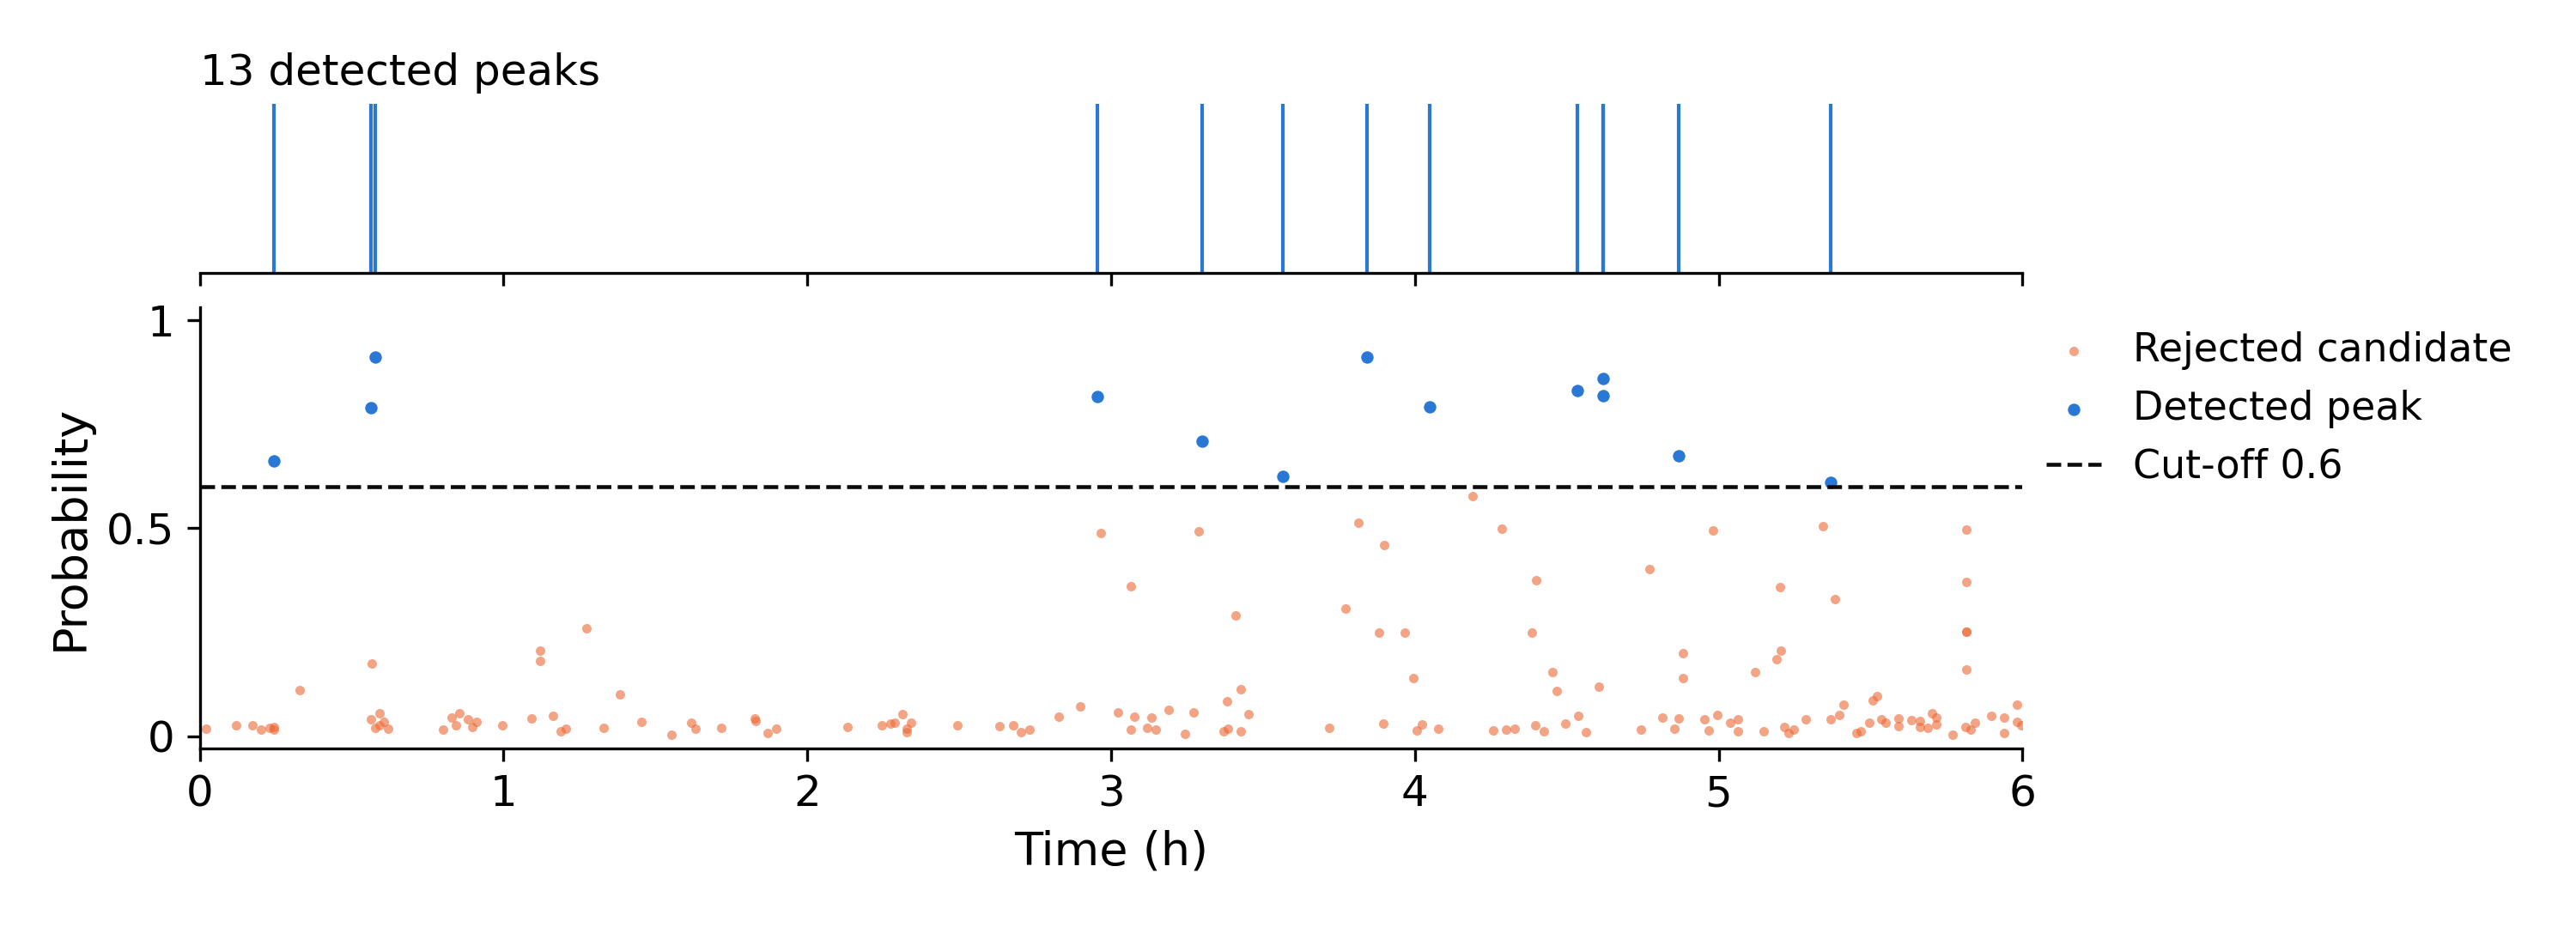

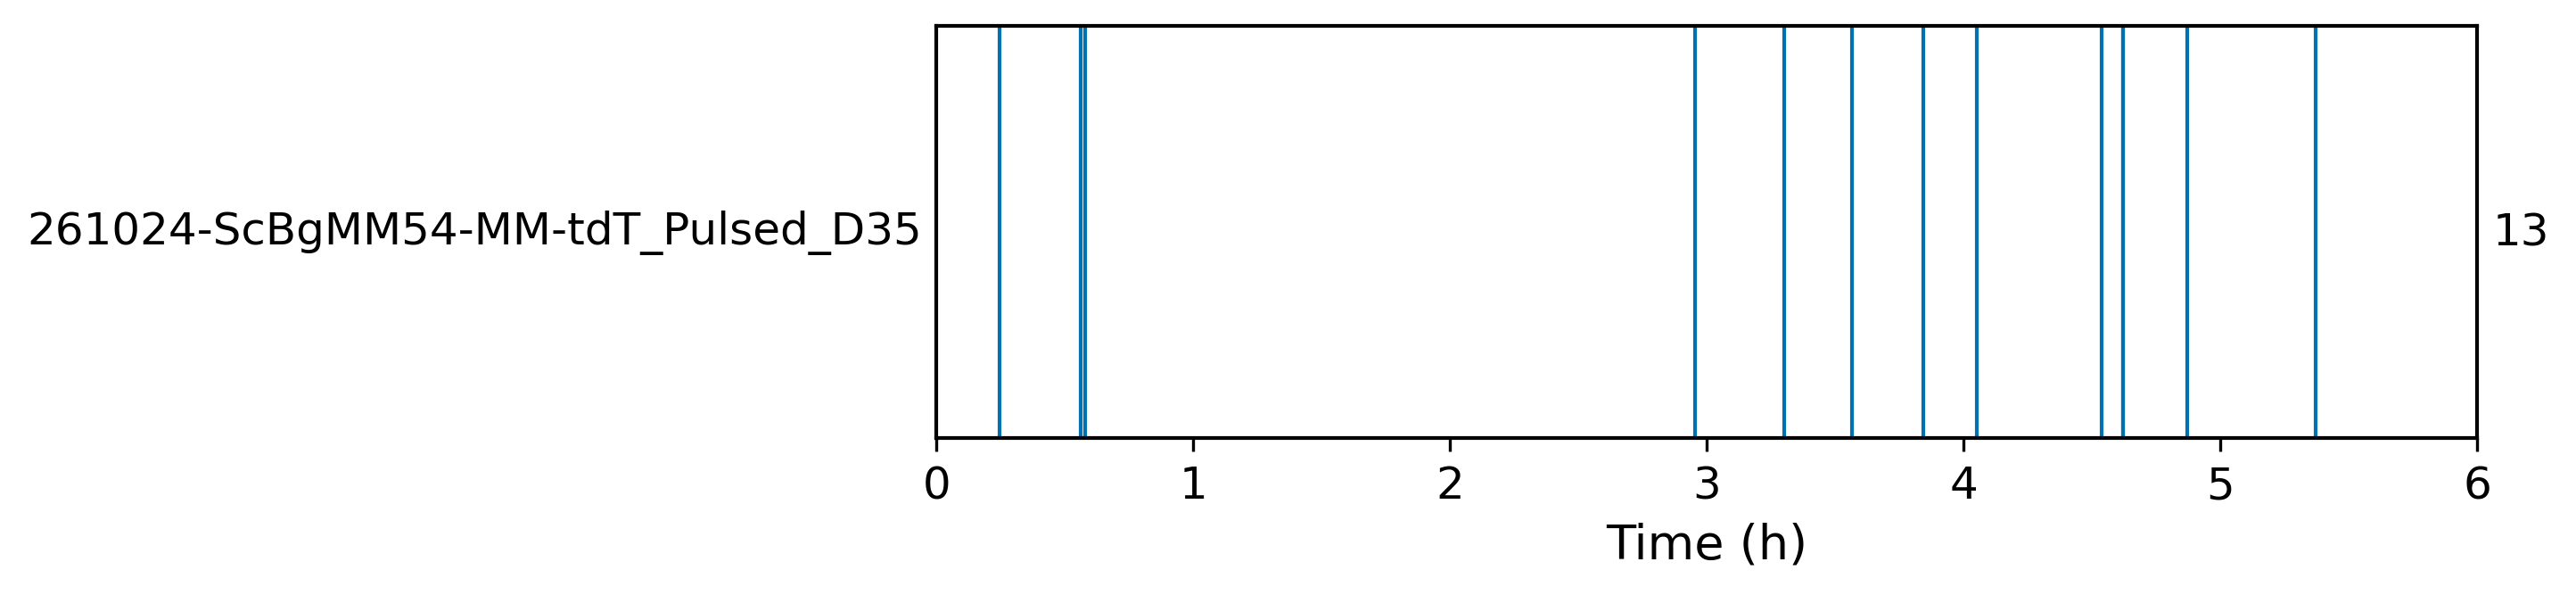

In [6]:
for name in ("timeline", "barcode"):
    display(Image(os.path.join(OUT, f"{name}.png"), width=900))

## Peak candidates

`candidates.csv`: every candidate with its time, source file, laser-edge flag, `file_in_splits` and the 5-seed mean probability. `detected` = probability ≥ cut-off, from a file that is not in the train/val/test splits.

In [7]:
d = pd.read_csv(os.path.join(OUT, "candidates.csv"))
w = np.load(os.path.join(mc.PULSED_PREP_DIR, SCAN, f"{SCAN}_windows.npz"))
raw, M = w["raw"], w["M"]                     # (N, 2, 2001) raw mV; mask True = laser OFF / zero-padding
assert np.array_equal(w["peaks"], d.peak_index.values)
P_COL = f"p_{mc.MODEL}"
print(f"{len(d)} candidates, {int(d.detected.sum())} detected, "
      f"{int(((d[P_COL] >= mc.NEAR_MISS) & ~d.detected).sum())} near misses ({mc.NEAR_MISS} <= p < {mc.CUT})")
d

173 candidates, 13 detected, 3 near misses (0.5 <= p < 0.6)


,peak_index,time_h,source_file,at_laser_edge,file_in_splits,p_fusion_lr1e-4_wd_ls,detected
0,157080,0.021817,261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat,False,False,0.017931,False
1,867786,0.120526,261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat,False,False,0.026225,False
2,1256481,0.174511,261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat,False,False,0.026664,False
3,1458524,0.202573,261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat,False,False,0.016317,False
4,1660443,0.230617,261024-ScBgMM54-MM-tdT_Pulsed_D35_1_F1.mat,False,False,0.019154,False
...,...,...,...,...,...,...,...
168,42762758,5.939272,261024-ScBgMM54-MM-tdT_Pulsed_D35_5_F1.mat,False,False,0.043603,False
169,42769879,5.940261,261024-ScBgMM54-MM-tdT_Pulsed_D35_5_F1.mat,False,False,0.006852,False
170,43064031,5.981115,261024-ScBgMM54-MM-tdT_Pulsed_D35_5_F1.mat,False,False,0.033884,False
171,43070075,5.981955,261024-ScBgMM54-MM-tdT_Pulsed_D35_5_F1.mat,False,False,0.075295,False


## 1-s window of every candidate

Raw Ch1 / Ch2 (mV), ±500 ms around the candidate (at 0 ms); grey = laser OFF or outside the recording. Each title: candidate number, time, probability, and `edge` / `in splits` when the candidate is within 25 ms of a laser edge or comes from a file already in the train/val/test splits.

In [8]:
def plot_windows(idx, label, per_page=WINDOWS_PER_PAGE, ncol=4):
    t = (np.arange(raw.shape[-1]) - raw.shape[-1] // 2) / mc.FS * 1e3
    for start in range(0, len(idx), per_page):
        chunk = idx[start:start + per_page]
        nrow = int(np.ceil(len(chunk) / ncol))
        fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 2.3 * nrow), squeeze=False)
        for ax, i in zip(axes.ravel(), chunk):
            r = d.iloc[i]
            ax.fill_between(t, 0, 1, where=M[i], transform=ax.get_xaxis_transform(), color="0.85", lw=0)
            ax.plot(t, raw[i, 1], color=sf.ART, lw=0.6, label="Ch2")
            ax.plot(t, raw[i, 0], color=sf.PEAK, lw=0.7, label="Ch1")
            flags = [f for f, on in (("edge", r.at_laser_edge), ("in splits", r.file_in_splits)) if on]
            ax.set_title(f"#{i}  {r.time_h:.3f} h  p = {r[P_COL]:.3f}" + (f"  ({', '.join(flags)})" if flags else ""),
                         fontsize=9, color=sf.PEAK if r.detected else sf.ART)
            ax.set_xlim(t[0], t[-1])
            ax.set_xticks([-500, -250, 0, 250, 500])
            ax.tick_params(labelsize=8)
        for ax in axes.ravel()[len(chunk):]:
            ax.axis("off")
        for ax in axes[:, 0]:
            ax.set_ylabel("Signal (mV)", fontsize=9)
        for ax in axes[-1]:
            ax.set_xlabel("Time (ms)", fontsize=9)
        h, l = axes[0, 0].get_legend_handles_labels()
        fig.legend(h[::-1], l[::-1], loc="upper right", ncol=2, frameon=False, fontsize=9)
        fig.suptitle(f"{SCAN}: {label} {start + 1}-{start + len(chunk)} of {len(idx)}", x=0.01, ha="left",
                     fontsize=10)
        fig.tight_layout()
        plt.show()



def show(mask, label):
    """Plot the candidates where mask is True, sorted by SORT_BY, at most MAX_WINDOWS."""
    order = d[mask].sort_values("time_h" if SORT_BY == "time" else P_COL, ascending=SORT_BY == "time").index
    idx = list(order[:MAX_WINDOWS] if MAX_WINDOWS else order)
    print(f"{label}: plotting {len(idx)} of {int(mask.sum())} (sorted by {SORT_BY})")
    if idx:
        plot_windows(idx, label)

### Detected peaks (p ≥ cut-off)

The candidates counted as peaks (`detected` in `candidates.csv`): probability ≥ cut-off, from a file that is not in the splits. Blue titles.

detected peaks: plotting 13 of 13 (sorted by time)


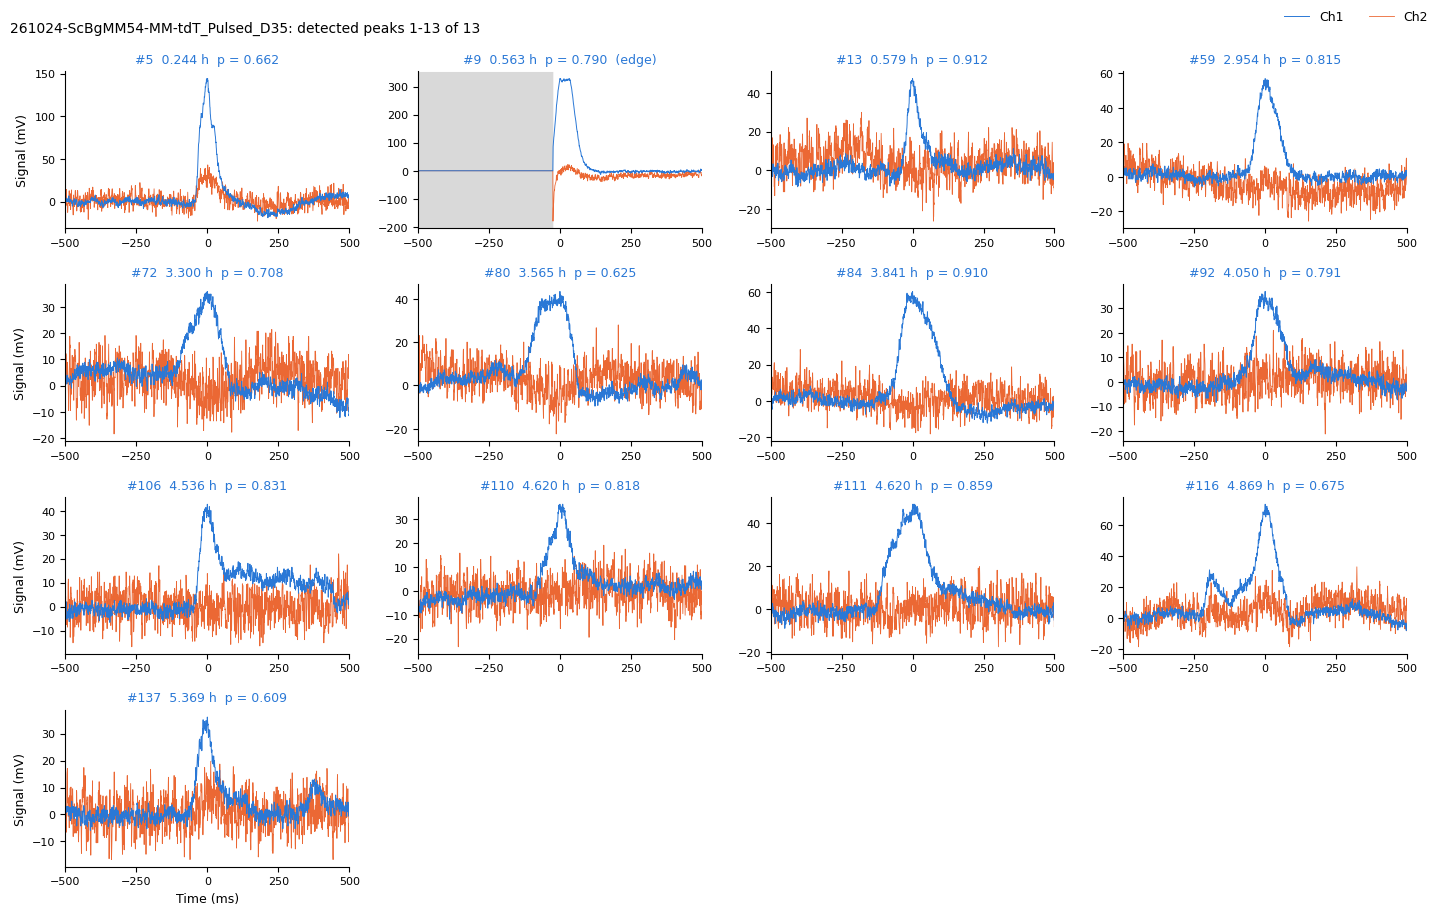

In [9]:
show(d.detected.values, "detected peaks")

### Artifacts (p < cut-off)

The rejected candidates. Orange titles; near misses (0.5 ≤ p < cut-off) are the ones closest to the cut-off (`SORT_BY = "probability"` lists them first).

artifacts: plotting 160 of 160 (sorted by time)


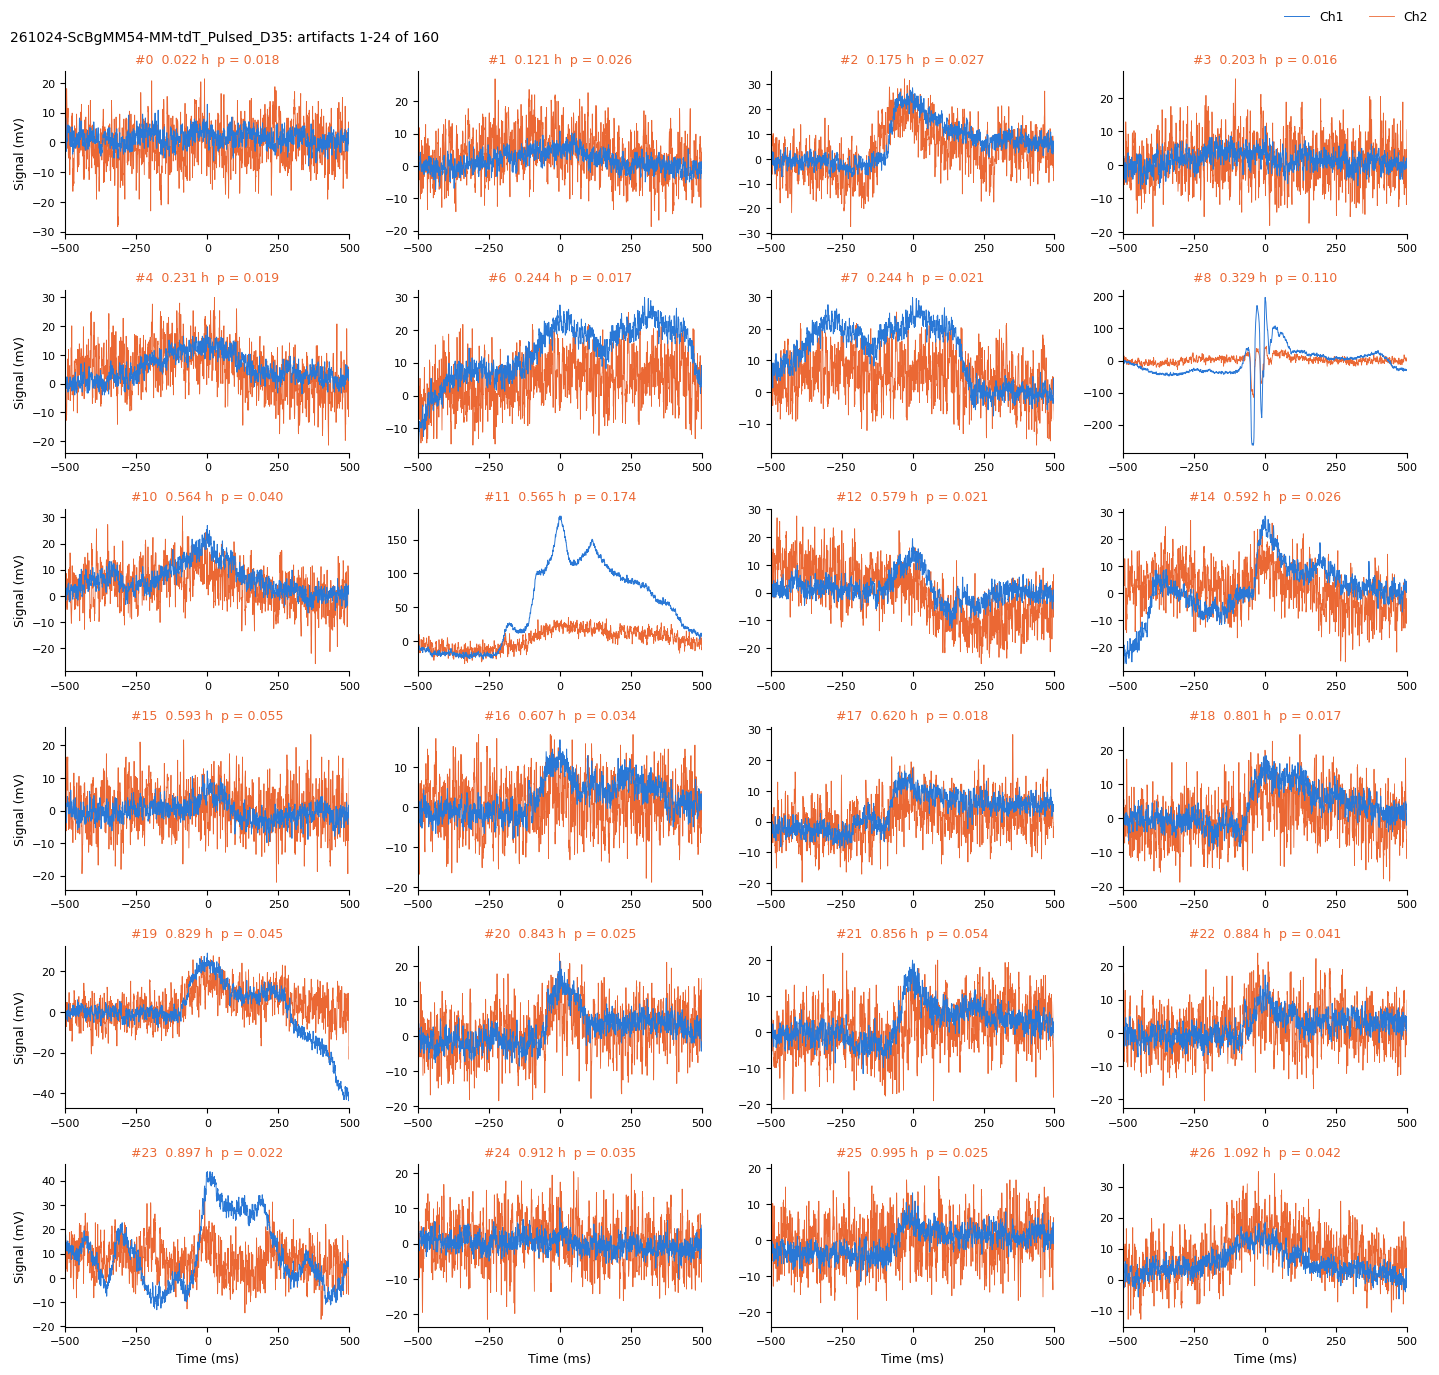

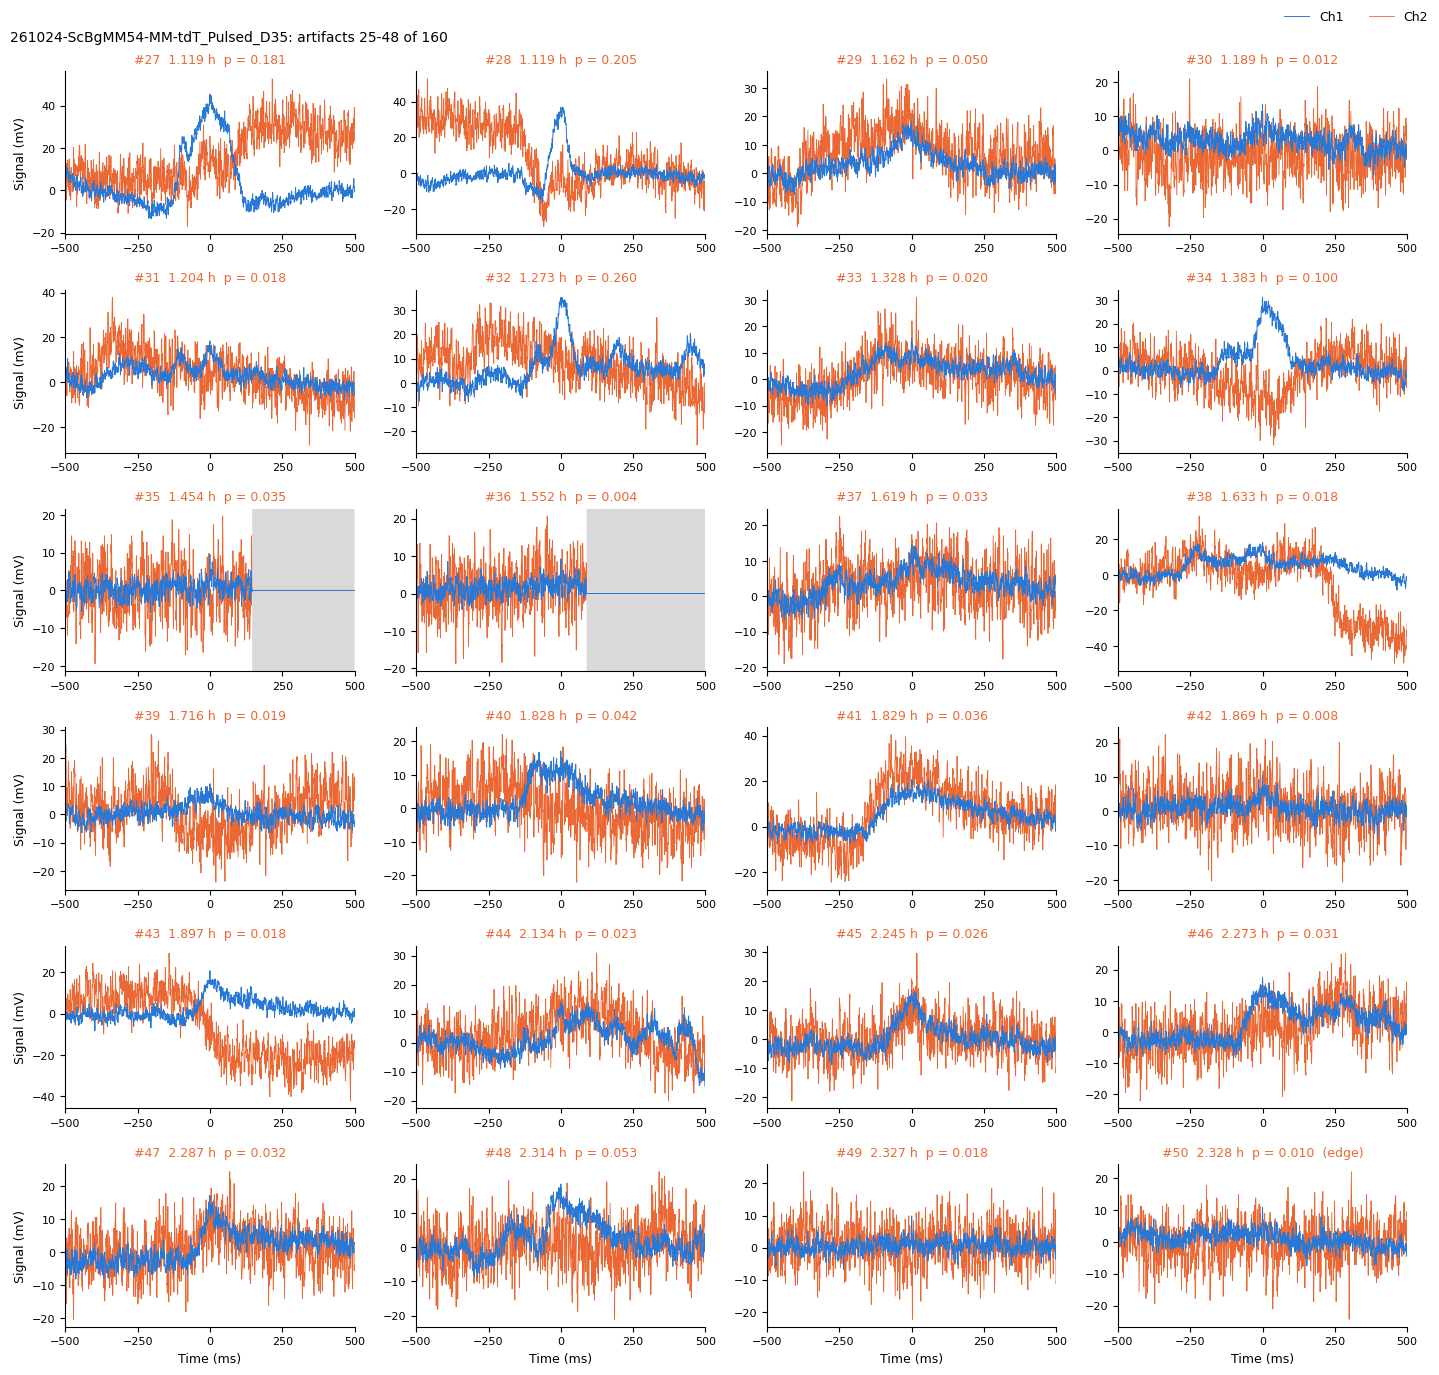

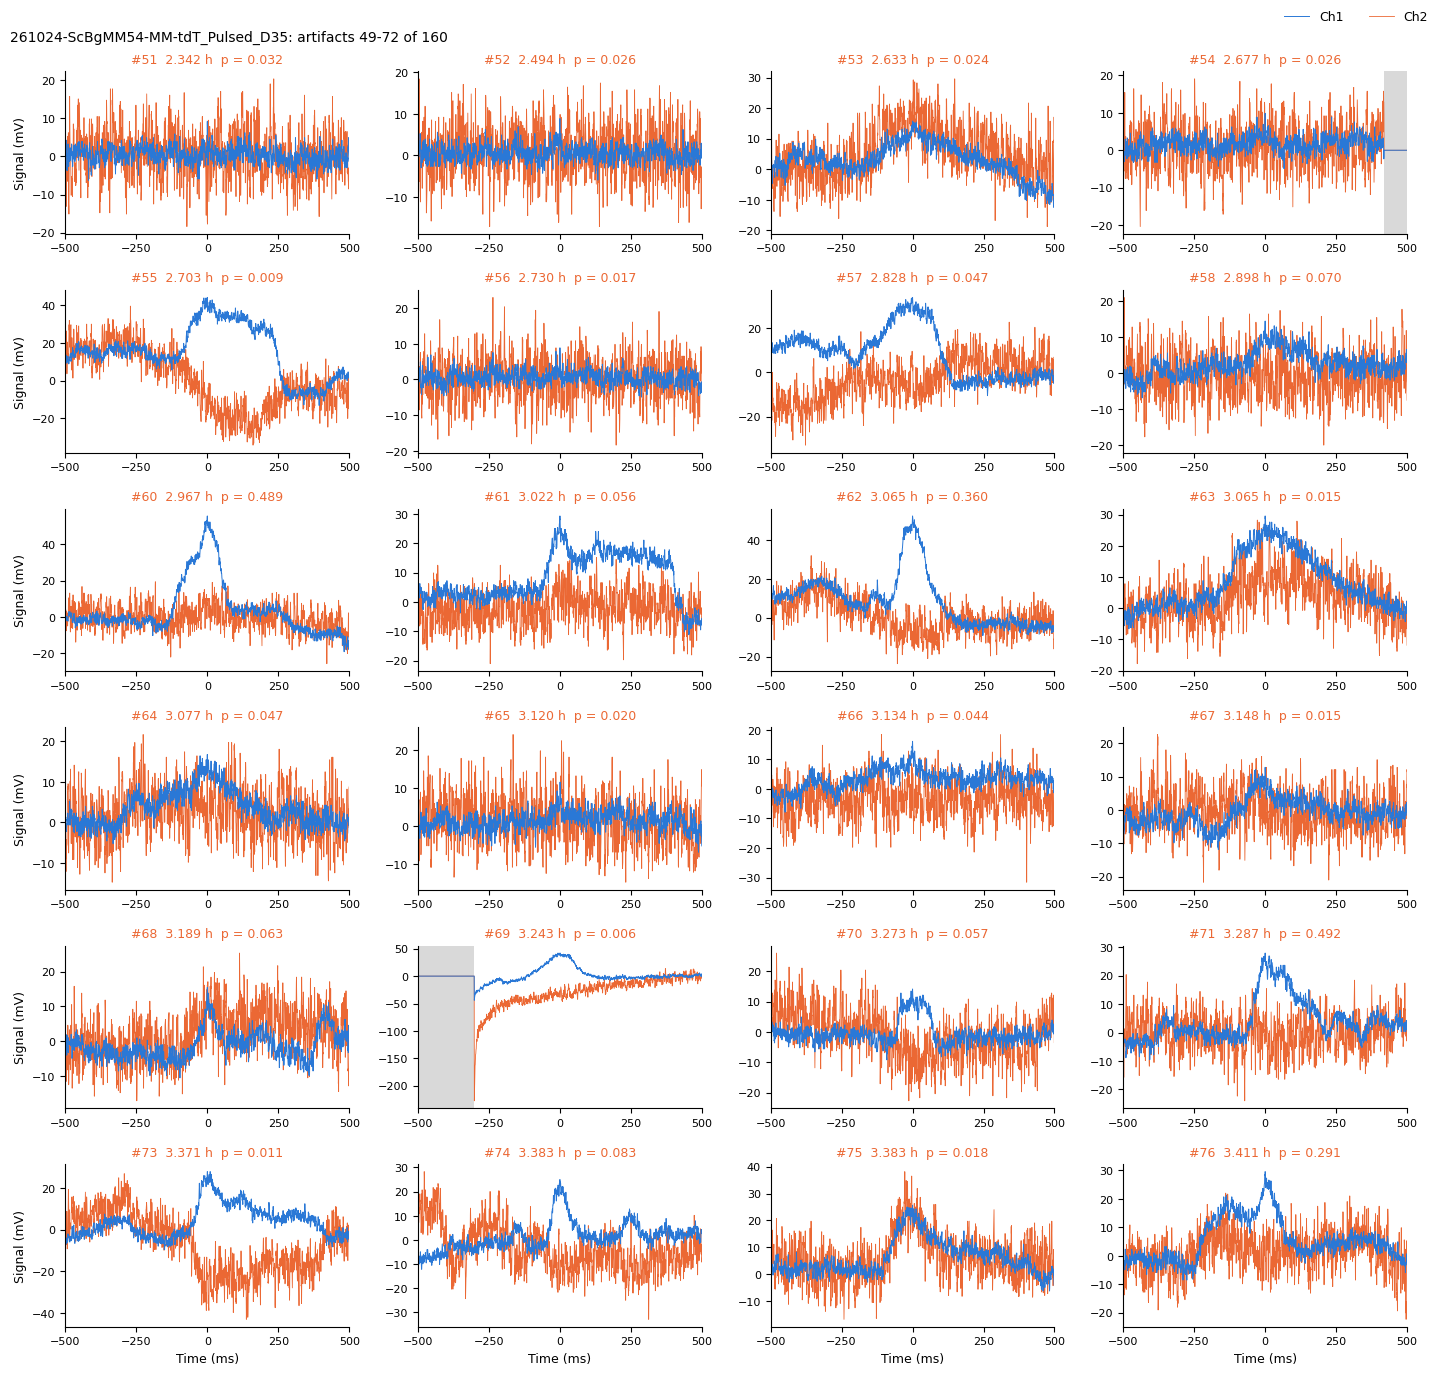

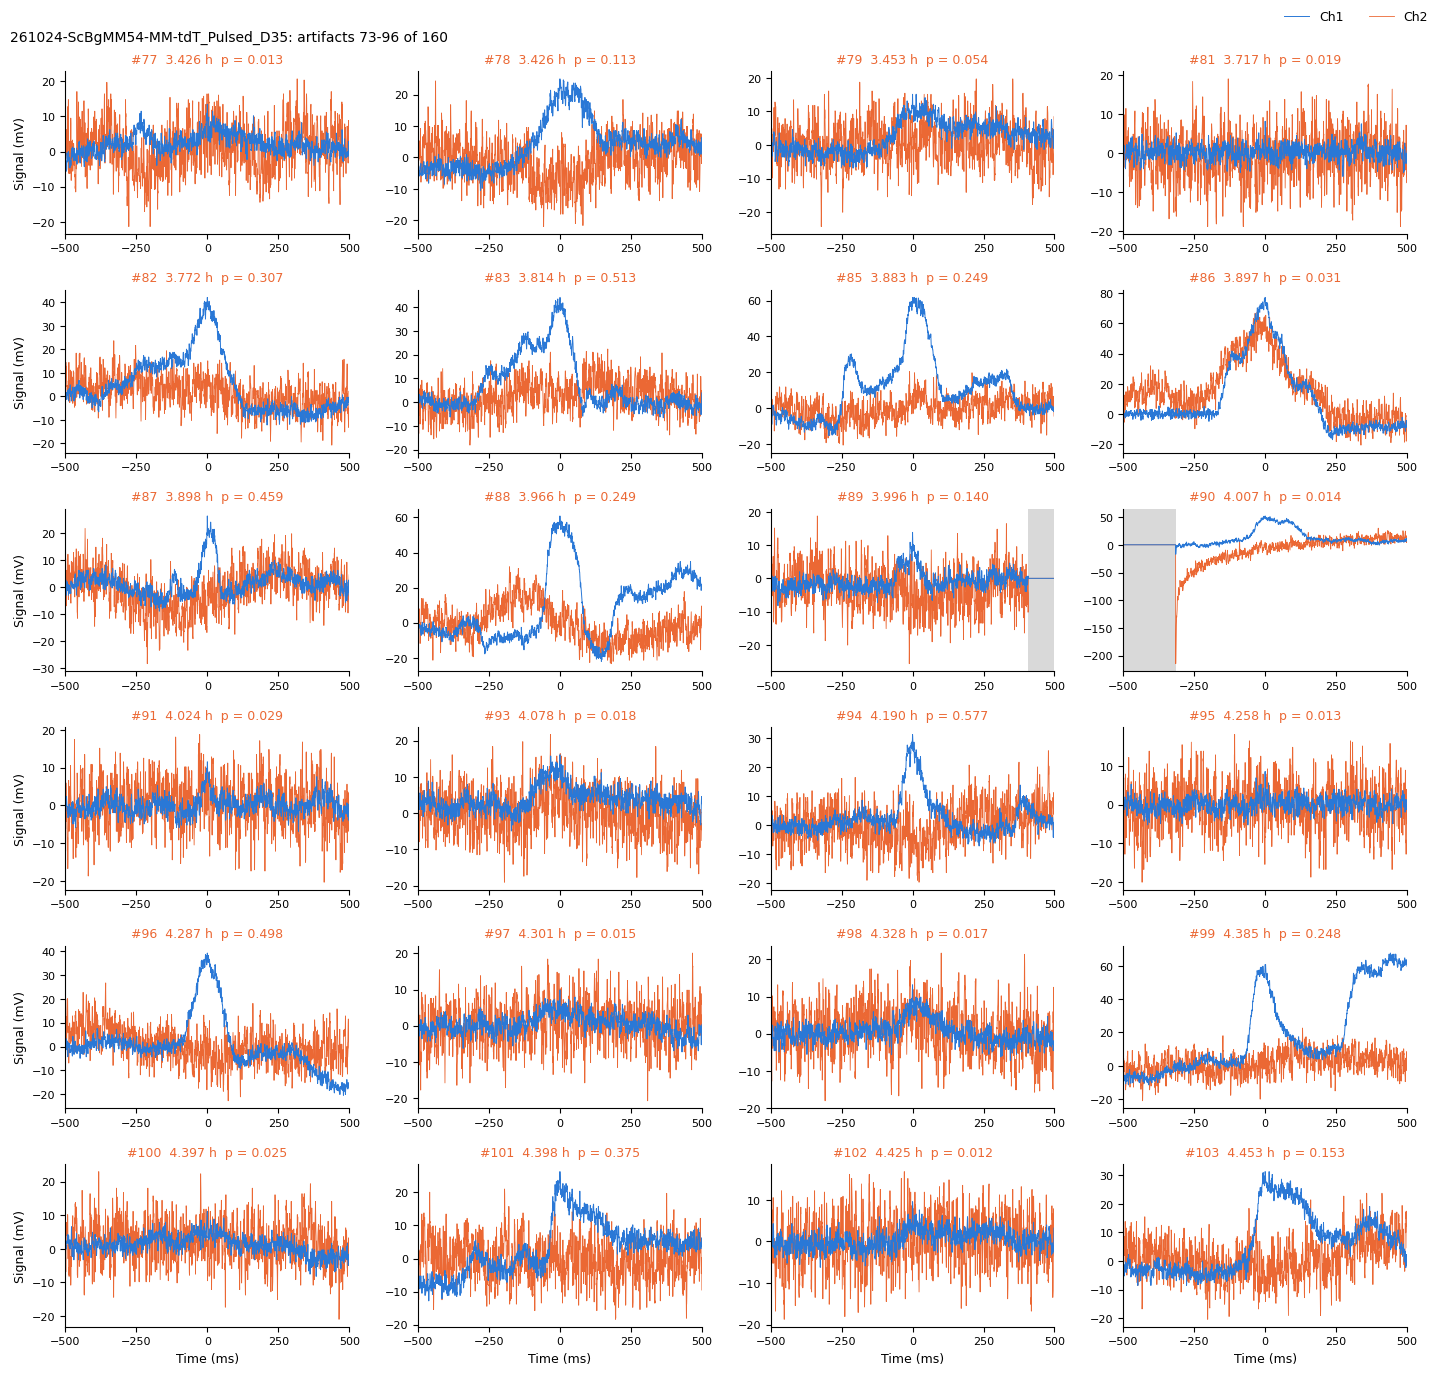

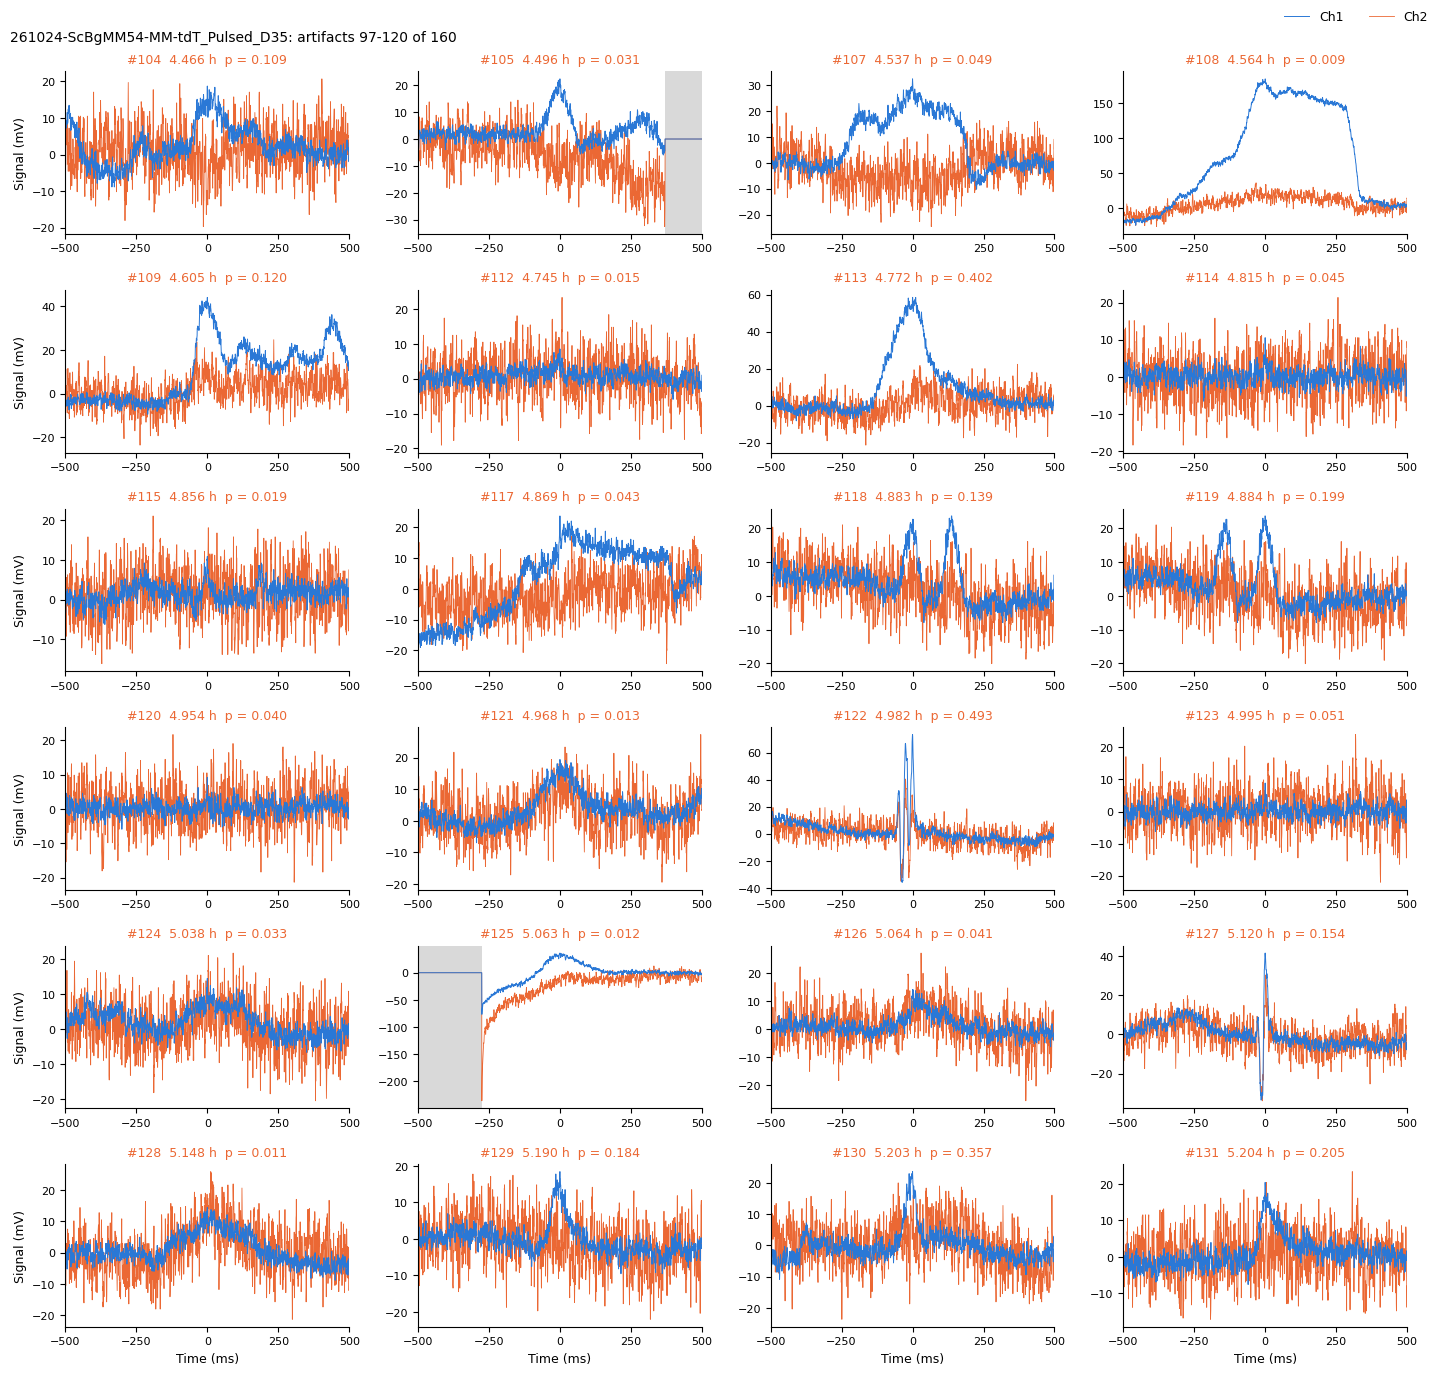

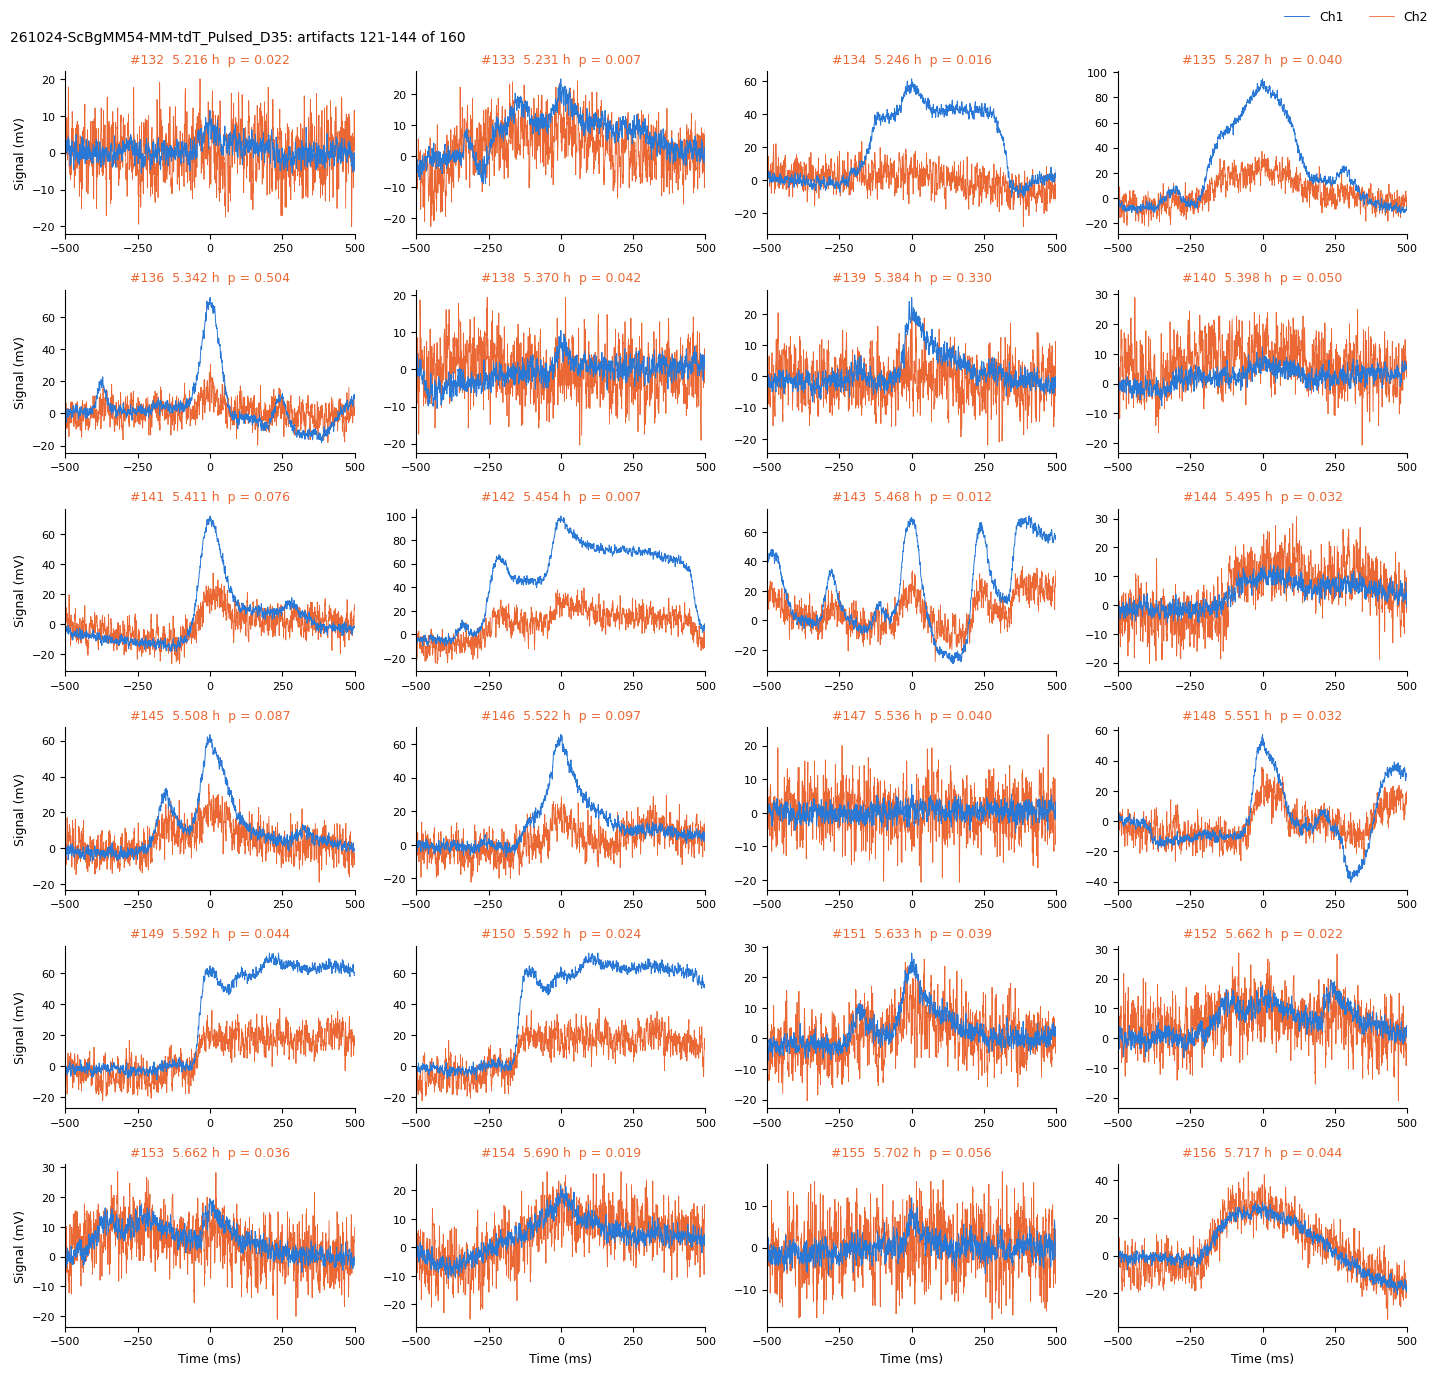

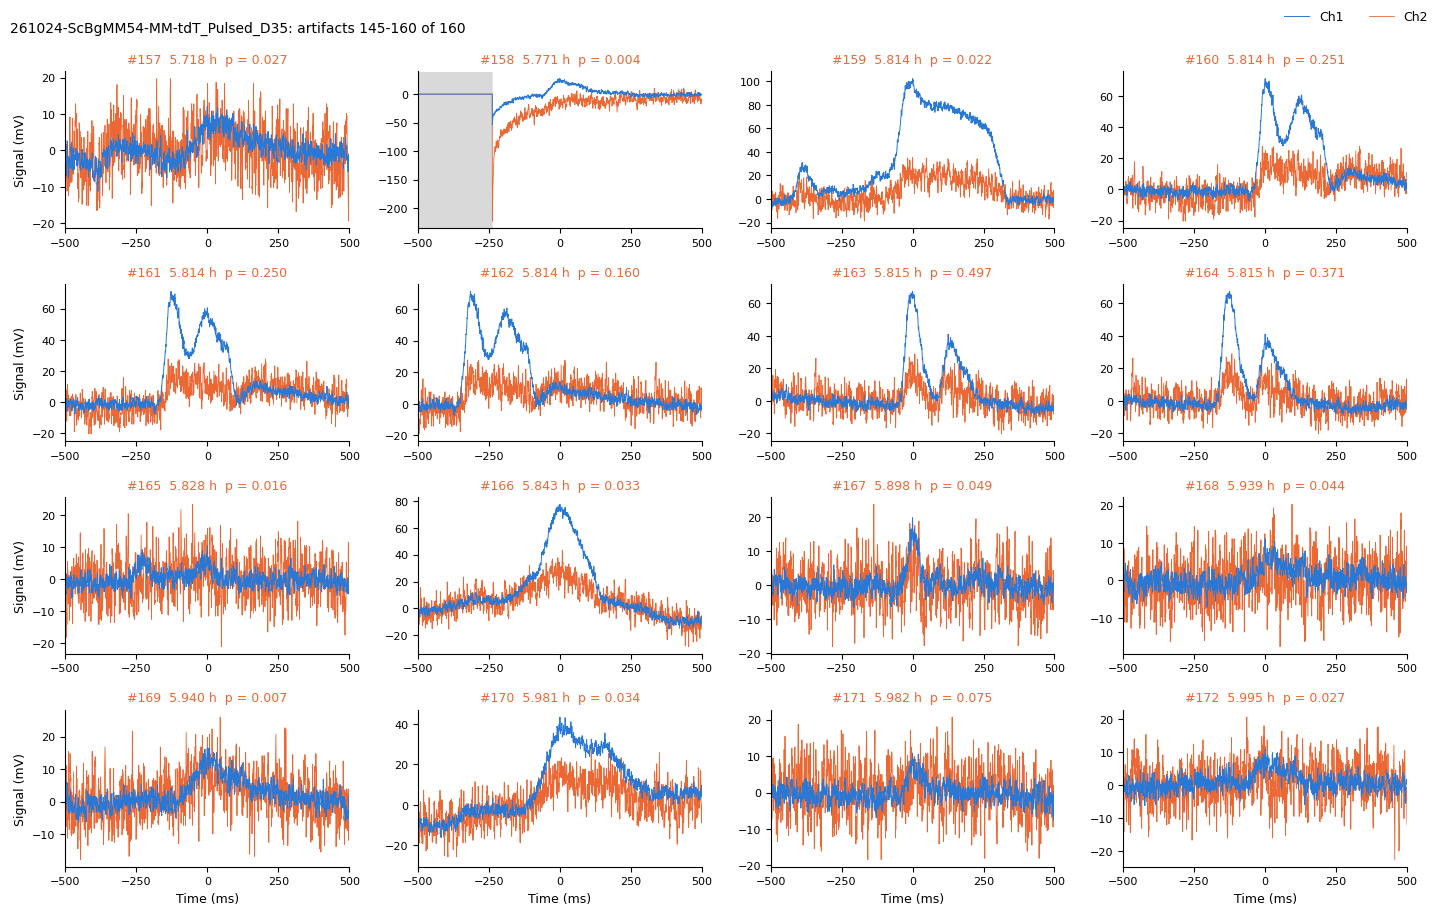

In [10]:
show((d[P_COL] < mc.CUT).values, "artifacts")
n_split = int(((d[P_COL] >= mc.CUT) & d.file_in_splits).sum())
if n_split:
    print(f"({n_split} candidates with p >= cut-off are from files in the splits; they are in neither cell)")